# 01 · Exploratory Data Analysis: Netflix Top 10 survival

**Goal:** understand the Netflix weekly global Top 10 data before building the pipeline. Each section answers a question that feeds a later design decision:

| Section | Question | Feeds into |
| --- | --- | --- |
| 1 | What does the raw file look like? | Pandera schema (Phase 2) |
| 2 | What's missing, and since when? | Feature choices, real drift story |
| 3 | How do we identify a title across weeks? | Feature table key |
| 4 | How often does a title survive to next week? | Label, metric choice |
| 5 | How does survival depend on rank? | Baseline rule |
| 6 | What do hours viewed and runtime look like? | Features, validation rules |
| 7 | Does anything shift over time? | Monitoring and drift plan |
| 8 | How good is the rank baseline? | The bar the model must beat |

**Data:** Netflix's global weekly Top 10 file (e.g. `2026-10-23_global_weekly.xlsx`), saved in `data/raw/`. One row per title per week per list (4 lists × 10 ranks per week).

## 0 · Setup

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_score, recall_score

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

# Netflix switched its Top 10 ranking from hours viewed to views on this date.
METRIC_SWITCH = pd.Timestamp("2023-06-18")

# Find the newest raw snapshot of the global weekly file (Excel or TSV).
# Works whether the notebook runs from notebooks/ or the repo root.
RAW_DIR = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")
candidates = sorted(
    [p for p in RAW_DIR.glob("*")
     if "global" in p.name.lower()
     and p.suffix.lower() in {".xlsx", ".tsv"}
     and not p.name.startswith(("~$", "."))]   # skip Excel's temporary lock files (~$...) while the file is open
)
if not candidates:
    raise FileNotFoundError(
        f"No global weekly file (.xlsx or .tsv with 'global' in its name) found in {RAW_DIR.resolve()}. "
        "Save Netflix's global weekly Top 10 file there (or run `dvc pull` once the data is versioned)."
    )
DATA_PATH = candidates[-1]   # names start with the date, so the last one is the newest
print("Using:", DATA_PATH)

Using: ..\data\raw\2026-10-23_global_weekly.xlsx


## 1 · First look at the raw file

Check the columns, types, and row counts. Each week should have exactly 40 rows (4 lists × 10 ranks); anything else is a data-quality issue the Pandera schema should catch.

In [ ]:
# Standard column names used by the rest of the notebook, plus other spellings
# the Excel file might use. Headings are lowercased and spaces become underscores first.
ALIASES = {
    "week": ["week", "week_ending", "week_of"],
    "category": ["category", "list"],
    "weekly_rank": ["weekly_rank", "rank"],
    "show_title": ["show_title", "title"],
    "season_title": ["season_title", "season"],
    "weekly_hours_viewed": ["weekly_hours_viewed", "hours_viewed"],
    "runtime": ["runtime", "runtime_hours"],
    "weekly_views": ["weekly_views", "views"],
    "cumulative_weeks_in_top_10": ["cumulative_weeks_in_top_10", "weeks_in_top_10", "cumulative_weeks"],
}


def load_raw(path):
    # Excel downloads sometimes have title rows above the real header: find the row containing "rank".
    if path.suffix.lower() == ".xlsx":
        preview = pd.read_excel(path, header=None, nrows=20)
        header_row = next(
            (i for i, row in preview.iterrows() if row.astype(str).str.contains("rank", case=False).any()), 0
        )
        df = pd.read_excel(path, header=header_row)
    else:
        df = pd.read_csv(path, sep="\t")

    # Normalise headings, e.g. "Weekly Hours Viewed" -> "weekly_hours_viewed"
    df.columns = (
        df.columns.astype(str).str.strip().str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")
    )
    rename = {alias: std for std, names in ALIASES.items() for alias in names if alias in df.columns and alias != std}
    df = df.rename(columns=rename).dropna(how="all")
    return df


raw = load_raw(DATA_PATH)
print("Columns found:", list(raw.columns))

required = ["week", "category", "weekly_rank", "show_title", "weekly_hours_viewed", "cumulative_weeks_in_top_10"]
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise KeyError(f"Couldn't find columns {missing_cols}. Add their spelling to ALIASES above.")
for optional in ["season_title", "runtime", "weekly_views"]:
    if optional not in raw.columns:
        raw[optional] = np.nan
        print(f"Note: '{optional}' not in file; filled with blanks.")

raw["week"] = pd.to_datetime(raw["week"])

print(f"{len(raw):,} rows × {raw.shape[1]} columns")
print(f"Weeks: {raw['week'].min().date()} to {raw['week'].max().date()} ({raw['week'].nunique()} weeks)")
raw.dtypes.to_frame("dtype")

c:\Users\Shann\miniconda3\envs\mlops\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
c:\Users\Shann\miniconda3\envs\mlops\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Columns found: ['week', 'category', 'weekly_rank', 'show_title', 'season_title', 'weekly_hours_viewed', 'runtime', 'weekly_views', 'cumulative_weeks_in_top_10']
11,080 rows × 9 columns
Weeks: 2021-07-04 to 2026-10-18 (277 weeks)


,dtype
week,datetime64[us]
category,str
weekly_rank,int64
show_title,str
season_title,str
weekly_hours_viewed,int64
runtime,float64
weekly_views,float64
cumulative_weeks_in_top_10,int64


In [ ]:
raw.head(10)

,week,category,weekly_rank,show_title,season_title,weekly_hours_viewed,runtime,weekly_views,cumulative_weeks_in_top_10
0,2026-10-18,Films (English),1,Animals,NaN,55400000,1.8000,30800000.0,2
1,2026-10-18,Films (English),2,Doing Life,NaN,13100000,1.8000,7300000.0,3
2,2026-10-18,Films (English),3,Ice Age: Collision Course,NaN,10200000,1.6167,6300000.0,5
3,2026-10-18,Films (English),4,Ice Age: Dawn of the Dinosaurs,NaN,7800000,1.5833,4900000.0,5
4,2026-10-18,Films (English),5,Ice Age,NaN,6600000,1.3833,4800000.0,2
5,2026-10-18,Films (English),6,Corpse Bride,NaN,5900000,1.2833,4600000.0,1
6,2026-10-18,Films (English),7,Anyone But You,NaN,7700000,1.7333,4400000.0,4
7,2026-10-18,Films (English),8,Ice Age: Continental Drift,NaN,6500000,1.5167,4300000.0,2
8,2026-10-18,Films (English),9,UNABOMBER,NaN,7000000,1.6667,4200000.0,4
9,2026-10-18,Films (English),10,Ice Age: The Meltdown,NaN,5600000,1.5500,3600000.0,2


In [ ]:
# Lists (categories) and how many rows each week has per list
print(raw["category"].value_counts(), "\n")

rows_per_week = raw.groupby(["week", "category"]).size()
print("Rows per week per list:", rows_per_week.value_counts().to_dict())
print("Rank range:", raw["weekly_rank"].min(), "to", raw["weekly_rank"].max())

category
Films (English)        2770
Films (Non-English)    2770
TV (English)           2770
TV (Non-English)       2770
Name: count, dtype: int64 

Rows per week per list: {10: 1108}
Rank range: 1 to 10


## 2 · Missing values

Which columns have gaps, and do the gaps cluster in time? `weekly_views` is expected to be empty before Netflix's June 2023 metric switch. If so, it can't be a model feature for the whole dataset, but the switch itself is a real-world drift event for monitoring.

In [ ]:
missing = raw.isna().mean().mul(100).round(1).sort_values(ascending=False)
missing.to_frame("% missing")

,% missing
season_title,51.5
weekly_views,36.8
runtime,36.8
week,0.0
category,0.0
show_title,0.0
weekly_rank,0.0
weekly_hours_viewed,0.0
cumulative_weeks_in_top_10,0.0


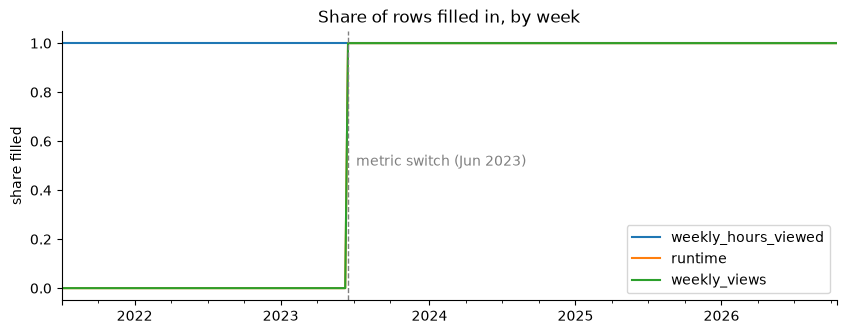

weekly_hours_viewed: first filled in 2021-07-04
runtime: first filled in 2023-06-18
weekly_views: first filled in 2023-06-18


In [ ]:
# Share of rows with each numeric column filled in, per week
numeric_cols = [c for c in ["weekly_hours_viewed", "runtime", "weekly_views"] if c in raw.columns]
filled = raw.groupby("week")[numeric_cols].apply(lambda g: g.notna().mean())

ax = filled.plot(figsize=(10, 3.5))
ax.axvline(METRIC_SWITCH, color="grey", linestyle="--", linewidth=1)
ax.text(METRIC_SWITCH, 0.5, "  metric switch (Jun 2023)", color="grey")
ax.set(title="Share of rows filled in, by week", ylabel="share filled", xlabel="")
plt.show()

for col in numeric_cols:
    first = raw.loc[raw[col].notna(), "week"].min()
    print(f"{col}: first filled in {first.date() if pd.notna(first) else 'never'}")

## 3 · Identifying a title across weeks

TV shows appear once per season (`season_title`), and films usually have `season_title` set to "N/A" or empty. The key that tracks "the same title" from week to week is **list + show + season**. Check that this key is unique within a week; duplicates would break the label.

In [ ]:
df = raw.copy()
df["season_title"] = df["season_title"].fillna("N/A")
df["title_key"] = df["category"] + " | " + df["show_title"] + " | " + df["season_title"]

dupes = df.duplicated(["week", "title_key"]).sum()
print(f"Duplicate (week, title) rows: {dupes}")
print(f"Unique titles: {df['title_key'].nunique():,}")
df["title_key"].value_counts().head(10).to_frame("weeks in data")

Duplicate (week, title) rows: 0
Unique titles: 4,032


,weeks in data
title_key,
Films (English) | KPop Demon Hunters | N/A,67
TV (Non-English) | Squid Game | Squid Game: Season 1,32
"TV (Non-English) | Yo soy Betty, la fea | Yo soy Betty, la fea: Season 1",30
TV (English) | Stranger Things | Stranger Things 4,29
TV (English) | Wednesday | Wednesday: Season 1,28
TV (Non-English) | Café con aroma de mujer | Café con aroma de mujer: Season 1,28
Films (English) | The Boss Baby | N/A,27
TV (English) | Ms. Rachel | Ms. Rachel: Season 1,26
TV (English) | Manifest | Manifest: Season 1,25


## 4 · The label: does the title survive to next week?

**Label = 1** if the same title is on the same list the following week. The final week in the data has no "next week" yet, so it's dropped. Check the class balance overall and per list: if it's far from 50/50, accuracy is a poor metric, which is the justification for PR-AUC.

In [ ]:
# A title "survives" if (title_key, week + 7 days) exists
present = set(zip(df["title_key"], df["week"]))
df["survives"] = [
    int((k, w + pd.Timedelta(days=7)) in present) for k, w in zip(df["title_key"], df["week"])
]

last_week = df["week"].max()
labeled = df[df["week"] < last_week].copy()   # final week has no known label yet
print(f"Labeled rows: {len(labeled):,} (dropped {len(df) - len(labeled)} rows from the final week)")
print(f"Overall survival rate: {labeled['survives'].mean():.1%}\n")
labeled.groupby("category")["survives"].agg(["mean", "size"]).rename(columns={"mean": "survival rate", "size": "rows"})

Labeled rows: 11,040 (dropped 40 rows from the final week)
Overall survival rate: 57.9%



,survival rate,rows
category,,
Films (English),0.496377,2760
Films (Non-English),0.553261,2760
TV (English),0.604710,2760
TV (Non-English),0.662681,2760


## 5 · Survival by rank and by weeks on the chart

If survival falls steadily with rank, a simple rank rule is a strong baseline, and the model has to beat it. Weeks on the chart shows whether long-running titles keep surviving or tend to fade.

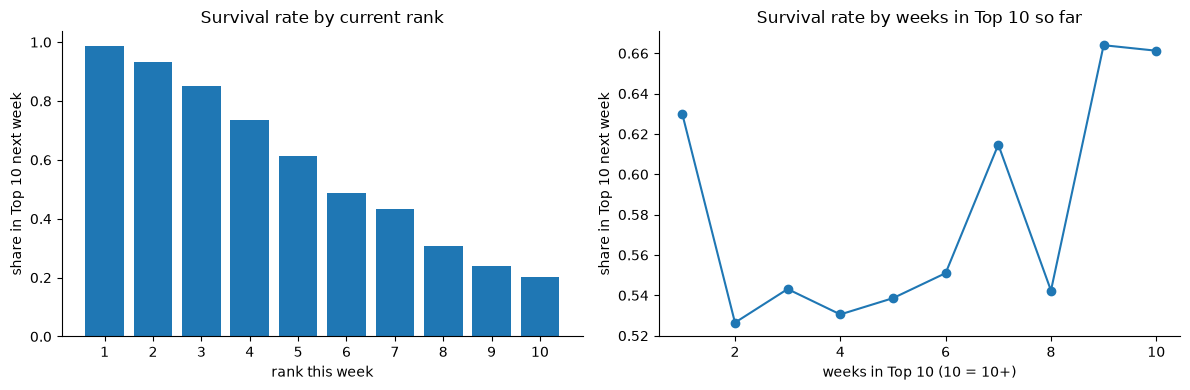

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

by_rank = labeled.groupby("weekly_rank")["survives"].mean()
axes[0].bar(by_rank.index, by_rank.values)
axes[0].set(title="Survival rate by current rank", xlabel="rank this week", ylabel="share in Top 10 next week", xticks=range(1, 11))

weeks_cap = labeled["cumulative_weeks_in_top_10"].clip(upper=10)
by_age = labeled.groupby(weeks_cap)["survives"].mean()
axes[1].plot(by_age.index, by_age.values, marker="o")
axes[1].set(title="Survival rate by weeks in Top 10 so far", xlabel="weeks in Top 10 (10 = 10+)", ylabel="share in Top 10 next week")
plt.tight_layout()
plt.show()

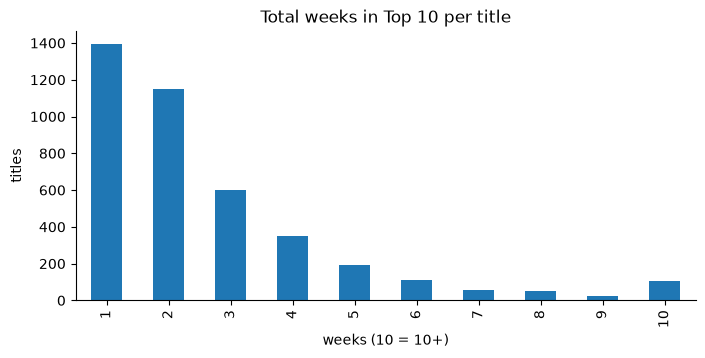

In [ ]:
# How long do titles last? (final run length per title, 10+ grouped)
run_length = df.groupby("title_key")["cumulative_weeks_in_top_10"].max().clip(upper=10)
ax = run_length.value_counts().sort_index().plot(kind="bar", figsize=(8, 3.5))
ax.set(title="Total weeks in Top 10 per title", xlabel="weeks (10 = 10+)", ylabel="titles")
plt.show()

## 6 · Hours viewed and runtime

Hours viewed is heavily skewed, so a log scale is easier to read (and `log(hours)` is likely a better model feature). Also check for values that should never happen: zero or negative hours, or zero runtime. These become Pandera rules and drift-test cases.

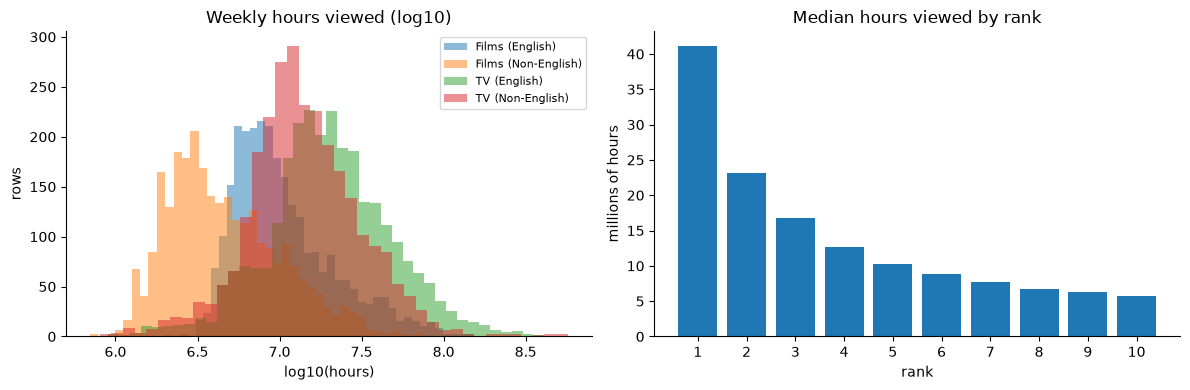

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for cat, g in labeled.groupby("category"):
    axes[0].hist(np.log10(g["weekly_hours_viewed"].clip(lower=1)), bins=40, alpha=0.5, label=cat)
axes[0].set(title="Weekly hours viewed (log10)", xlabel="log10(hours)", ylabel="rows")
axes[0].legend(fontsize=8)

hours_by_rank = labeled.groupby("weekly_rank")["weekly_hours_viewed"].median() / 1e6
axes[1].bar(hours_by_rank.index, hours_by_rank.values)
axes[1].set(title="Median hours viewed by rank", xlabel="rank", ylabel="millions of hours", xticks=range(1, 11))
plt.tight_layout()
plt.show()

In [ ]:
checks = {
    "hours viewed <= 0": (raw["weekly_hours_viewed"] <= 0).sum(),
    "runtime == 0": (raw["runtime"] == 0).sum() if "runtime" in raw else "n/a",
    "runtime missing": raw["runtime"].isna().sum() if "runtime" in raw else "n/a",
    "rank outside 1-10": (~raw["weekly_rank"].between(1, 10)).sum(),
    "weeks in Top 10 below 1": (raw["cumulative_weeks_in_top_10"] < 1).sum(),
}
pd.Series(checks, name="rows").to_frame()

,rows
hours viewed <= 0,0
runtime == 0,172
runtime missing,4080
rank outside 1-10,0
weeks in Top 10 below 1,0


In [ ]:
if "runtime" in raw:
    print(raw.groupby(raw["category"].str.startswith("TV"))["runtime"].describe().rename(index={True: "TV", False: "Films"}))

           count      mean       std   min      25%     50%     75%      max
category                                                                    
Films     3500.0  1.847976  0.364562  0.45  1.60000  1.7667  2.0167   3.8667
TV        3500.0  5.602537  3.612169  0.00  3.42915  5.2333  7.2500  47.5833


## 7 · Does anything shift over time?

Look for changes the monitoring setup should expect: survival rate drifting, hours viewed trending, and anything that changes at the June 2023 metric switch. These are candidate real-drift stories to set next to the synthetic corruptions.

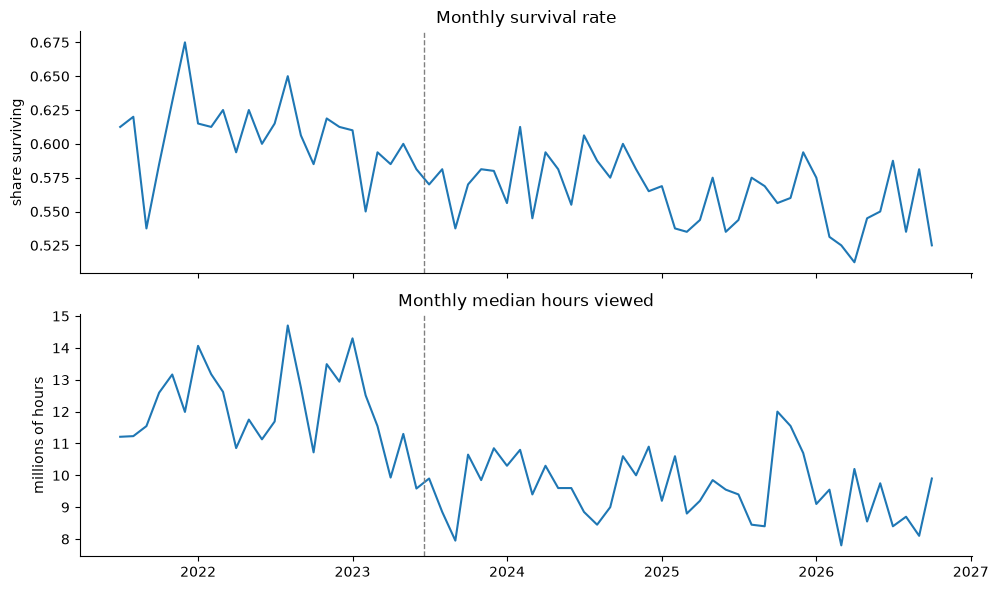

,before switch,after switch
survival rate,60.6%,56.3%
median hours viewed,12.1M,9.6M
rows,"4,080","6,960"


In [ ]:
monthly = labeled.set_index("week").resample("MS").agg({"survives": "mean", "weekly_hours_viewed": "median"})

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(monthly.index, monthly["survives"])
axes[0].set(title="Monthly survival rate", ylabel="share surviving")
axes[1].plot(monthly.index, monthly["weekly_hours_viewed"] / 1e6)
axes[1].set(title="Monthly median hours viewed", ylabel="millions of hours")
for ax in axes:
    ax.axvline(METRIC_SWITCH, color="grey", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

before = labeled[labeled["week"] < METRIC_SWITCH]
after = labeled[labeled["week"] >= METRIC_SWITCH]
summary = lambda g: [f"{g['survives'].mean():.1%}", f"{g['weekly_hours_viewed'].median() / 1e6:.1f}M", f"{len(g):,}"]
pd.DataFrame({"before switch": summary(before), "after switch": summary(after)},
             index=["survival rate", "median hours viewed", "rows"])

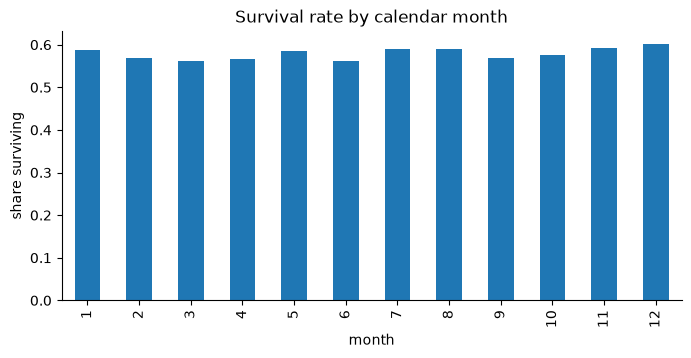

In [ ]:
# December effect: do holiday titles fade faster?
by_month = labeled.groupby(labeled["week"].dt.month)["survives"].mean()
ax = by_month.plot(kind="bar", figsize=(8, 3.5))
ax.set(title="Survival rate by calendar month", xlabel="month", ylabel="share surviving")
plt.show()

## 8 · Baseline preview and holdout

The planned baseline is **"rank 5 or better survives."** As a ranking score for PR-AUC, use `11 − rank` (rank 1 scores highest). The final baseline number is computed on the training weeks only in Phase 2; this is a preview.

The holdout is the **last 20 weeks**, set aside until production validation.

In [ ]:
weeks = np.sort(labeled["week"].unique())
holdout_start = weeks[-20]
train = labeled[labeled["week"] < holdout_start]
holdout = labeled[labeled["week"] >= holdout_start]
print(f"Train:   {train['week'].min().date()} to {train['week'].max().date()}  ({len(train):,} rows)")
print(f"Holdout: {holdout['week'].min().date()} to {holdout['week'].max().date()}  ({len(holdout):,} rows)\n")

rule = (train["weekly_rank"] <= 5).astype(int)
score = 11 - train["weekly_rank"]
pd.Series({
    "PR-AUC (score = 11 − rank)": average_precision_score(train["survives"], score),
    "Precision of rank ≤ 5 rule": precision_score(train["survives"], rule),
    "Recall of rank ≤ 5 rule": recall_score(train["survives"], rule),
    "PR-AUC of a coin flip (= survival rate)": train["survives"].mean(),
}, name="training weeks").round(3).to_frame()

Train:   2021-07-04 to 2026-05-24  (10,240 rows)
Holdout: 2026-05-31 to 2026-10-11  (800 rows)



,training weeks
PR-AUC (score = 11 − rank),0.859
Precision of rank ≤ 5 rule,0.826
Recall of rank ≤ 5 rule,0.711
PR-AUC of a coin flip (= survival rate),0.581
